# Fitness Dataset — Exploratory Data Analysis

**Target variable:** `Fitness Level` (High / Low)  
**Raw dataset:** 1 610 rows × 11 columns  

Simple pass: **data quality → look at distributions → explore features (alone, together, vs target) → short synthesis** for modelling.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 110})
sns.set_style('whitegrid')

df = pd.read_csv('fitness_dataset.csv')
print(f'Shape: {df.shape}')
df.head()


Shape: (1610, 11)


,Height,Age,Gender,Smoker,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight,Fitness Level
0,152.0,56.0,Female,No,3.97,NaN,69.6,2.37,117.0,65.0,High
1,186.0,69.0,Female,No,3.19,7.5,60.8,8.77,114.8,95.0,High
2,192.0,46.0,Female,No,2.03,NaN,61.4,8.20,116.4,103.0,Low
3,189.0,32.0,Male,No,NaN,7.0,60.2,6.18,130.1,83.0,High
4,175.0,60.0,Female,Yes,NaN,8.0,58.1,9.95,115.8,99.0,High


In [2]:
# quick look at types and basic stats — this tells me what I'm dealing with
print(df.dtypes)
print()
df.describe(include='all').T.round(2)

Height               float64
Age                  float64
Gender                object
Smoker                object
Activity Index       float64
Sleep Hours          float64
Heart Rate           float64
Nutrition Quality    float64
Blood Pressure       float64
Weight               float64
Fitness Level         object
dtype: object



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Height,1598.0,NaN,NaN,NaN,174.0801,14.380676,150.0,162.0,173.0,186.0,199.0
Age,1601.0,NaN,NaN,NaN,50.531543,17.870658,18.0,36.0,51.0,66.0,79.0
Gender,1598,2,Female,858,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Smoker,1600,2,No,808,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Activity Index,794.0,NaN,NaN,NaN,2.875982,1.127762,1.0,1.91,2.78,3.78,4.99
Sleep Hours,1467.0,NaN,NaN,NaN,7.431152,1.499842,4.0,6.4,7.4,8.5,12.0
Heart Rate,1476.0,NaN,NaN,NaN,70.233469,11.848808,45.0,62.375,70.1,78.3,118.6
Nutrition Quality,1601.0,NaN,NaN,NaN,4.846471,2.851291,0.0,2.42,4.73,7.21,10.0
Blood Pressure,1441.0,NaN,NaN,NaN,118.836572,18.142572,0.0,109.2,119.8,130.0,168.1
Weight,1600.0,NaN,NaN,NaN,84.2075,26.162062,30.0,64.0,84.0,103.0,250.0


---
## Section 1 — Data Quality

*Question: How much data is actually missing, are there any duplicate rows, and do any values look physiologically impossible?*

                   count  pct (%)
Activity Index       816    50.68
Blood Pressure       169    10.50
Sleep Hours          143     8.88
Heart Rate           134     8.32
Height                12     0.75
Gender                12     0.75
Smoker                10     0.62
Weight                10     0.62
Age                    9     0.56
Nutrition Quality      9     0.56
Fitness Level          0     0.00



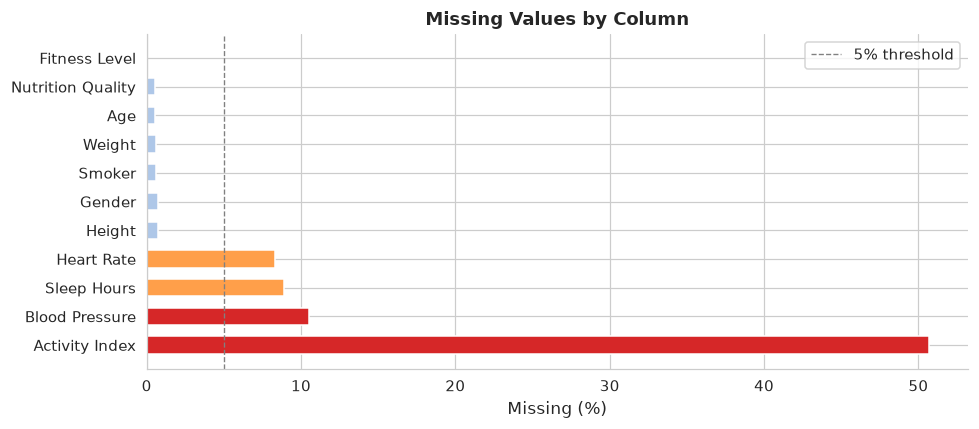

In [3]:
# missing values per column — count and percentage
missing = pd.DataFrame({
    'count':  df.isnull().sum(),
    'pct (%)': (df.isnull().mean() * 100).round(2)
}).sort_values('pct (%)', ascending=False)

print(missing)
print()

fig, ax = plt.subplots(figsize=(9, 4))
bar_colors = ['#d62728' if p > 10 else '#ff9f4a' if p > 1 else '#aec7e8'
              for p in missing['pct (%)']]
ax.barh(missing.index, missing['pct (%)'], color=bar_colors, height=0.6)
ax.axvline(5, color='gray', linestyle='--', linewidth=0.9, label='5% threshold')
ax.set_xlabel('Missing (%)', fontsize=11)
ax.set_title('Missing Values by Column', fontsize=12, fontweight='bold')
ax.legend()
for sp in ['top', 'right']:
    ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.show()

> **Standout issue:** `Activity Index` is missing for **50.7%** of rows — over half the column. That's not a small gap; it's a data collection problem. Everything else is under 11%.

### Duplicates & near-empty (ghost) rows

Exact duplicates inflate *n* without adding information. Ghost rows (≥80% NaN) have no usable features — drop both.


In [4]:
# --- Ghost rows ---
n_before = len(df)
thresh = int(0.8 * len(df.columns))
ghost_rows = df[df.isnull().sum(axis=1) >= thresh]
print(f'Rows with >=80% missing (ghost): {len(ghost_rows)}')
print(f'Indices: {ghost_rows.index.tolist()}')
print(ghost_rows.head().to_string())
print()

# --- Duplicates: show the actual row(s), not just a count ---
n_dup = int(df.duplicated().sum())
print(f'Exact duplicate rows: {n_dup}')
if n_dup > 0:
    print('Duplicate row(s) (keep=False so both copies are visible):')
    print(df[df.duplicated(keep=False)].to_string())
print()

df_clean = df.drop(index=ghost_rows.index).drop_duplicates().reset_index(drop=True)
print(f'After dropping ghost + duplicates: {df_clean.shape}  (was {n_before})')
print('Decision: DROP both — no analytical value; keeping them only inflates missingness / n.')


Rows with >=80% missing (ghost): 11
Indices: [18, 82, 197, 433, 635, 676, 754, 893, 980, 1233, 1580]
     Height  Age Gender Smoker  Activity Index  Sleep Hours  Heart Rate  Nutrition Quality  Blood Pressure  Weight Fitness Level
18      NaN  NaN    NaN    NaN            3.71          NaN         NaN                NaN             NaN     NaN          High
82      NaN  NaN    NaN    NaN             NaN          6.6         NaN               3.52             NaN     NaN           Low
197     NaN  NaN    NaN    NaN             NaN          NaN         NaN               2.72           116.6     NaN          High
433     NaN  NaN    NaN    NaN            2.07          NaN         NaN                NaN             NaN     NaN           Low
635     NaN  NaN    NaN    NaN             NaN          NaN         NaN                NaN             NaN     NaN           Low

Exact duplicate rows: 1
Duplicate row(s) (keep=False so both copies are visible):
     Height  Age Gender Smoker  Activity I

### Noise / anomalies — detect, decide, act

Focus is not only spotting odd values but **what we do about them**. Impossible readings (e.g. systolic BP = 0) are treated as missing.


In [5]:
print('=== Suspicious / Implausible Values ===')
print()

# Weight = 30 kg in adults — physiologically implausible
low_w = df_clean[df_clean['Weight'] < 35]
print(f'Weight < 35 kg: {len(low_w)} rows')
if len(low_w):
    print(low_w[['Weight', 'Height', 'Age', 'Fitness Level']].to_string())
print('  -> Adult 30 kg is not plausible. ACTION: clip Weight to [35, 161] for modelling.')
print()

high_w = df_clean[df_clean['Weight'] > 161]
print(f'Weight > 161 kg: {len(high_w)} rows (max={df_clean["Weight"].max()})')
print('  -> Extreme / likely unit or synthetic outliers (EDA fence). ACTION: clip upper to 161.')
print()

# Blood Pressure == 0 — impossible systolic
n_bp0 = int((df_clean['Blood Pressure'] == 0).sum())
print(f'Blood Pressure == 0: {n_bp0} rows')
if n_bp0:
    print(df_clean.loc[df_clean['Blood Pressure'] == 0,
                       ['Blood Pressure', 'Age', 'Fitness Level']].head().to_string())
print('  -> Systolic 0 mmHg is impossible (sensor/default). ACTION: set to NaN, then median-impute in ML.')
bp_miss_before = df_clean['Blood Pressure'].isna().mean() * 100
df_clean.loc[df_clean['Blood Pressure'] == 0, 'Blood Pressure'] = np.nan
bp_miss_after = df_clean['Blood Pressure'].isna().mean() * 100
print(f'  BP missing %: {bp_miss_before:.2f}% -> {bp_miss_after:.2f}% | new min={df_clean["Blood Pressure"].min():.1f}')
print()

# Resting HR > 100 bpm = tachycardia — keep
high_hr = df_clean[df_clean['Heart Rate'] > 100]
print(f'Resting HR > 100 bpm: {len(high_hr)} rows')
print('  -> Clinically unusual but possible. ACTION: KEEP.')
print()

# Sleep > 9.5 hrs — keep
high_sl = df_clean[df_clean['Sleep Hours'] > 9.5]
print(f'Sleep Hours > 9.5: {len(high_sl)} rows (max = {df_clean["Sleep Hours"].max()})')
print('  -> Plausible (shift work / hypersomnia). ACTION: KEEP.')
print()

# Apply weight clips so later EDA matches ML
df_clean['Weight'] = df_clean['Weight'].clip(lower=35, upper=161)
print('Weight clipped to [35, 161] on df_clean.')


=== Suspicious / Implausible Values ===

Weight < 35 kg: 4 rows
      Weight  Height   Age Fitness Level
20      30.0   181.0  50.0           Low
1062    30.0   174.0  74.0           Low
1190    30.0   168.0  53.0           Low
1401    30.0   177.0  51.0           Low
  -> Adult 30 kg is not plausible. ACTION: clip Weight to [35, 161] for modelling.

Weight > 161 kg: 18 rows (max=250.0)
  -> Extreme / likely unit or synthetic outliers (EDA fence). ACTION: clip upper to 161.

Blood Pressure == 0: 12 rows
     Blood Pressure   Age Fitness Level
265             0.0  51.0           Low
376             0.0  78.0           Low
780             0.0  67.0          High
785             0.0  53.0          High
927             0.0  57.0           Low
  -> Systolic 0 mmHg is impossible (sensor/default). ACTION: set to NaN, then median-impute in ML.
  BP missing %: 9.94% -> 10.69% | new min=90.0

Resting HR > 100 bpm: 16 rows
  -> Clinically unusual but possible. ACTION: KEEP.

Sleep Hours > 9.5: 10

### Quality decision table (handoff to ML / Resub 2)

Same rules must be applied in the modelling notebook.


In [6]:
decision_tbl = pd.DataFrame([
    {'Issue': 'Ghost rows (>=80% NaN)', 'Count': len(ghost_rows), 'Action': 'Drop',
     'Why': 'No usable features'},
    {'Issue': 'Exact duplicates', 'Count': n_dup, 'Action': 'Drop',
     'Why': 'Inflates n; no new information'},
    {'Issue': 'Blood Pressure == 0', 'Count': n_bp0, 'Action': 'Set to NaN → median impute',
     'Why': 'Impossible systolic; treat as missing'},
    {'Issue': 'Weight < 35', 'Count': len(low_w), 'Action': 'Clip to 35',
     'Why': 'Adult ~30 kg implausible entry error'},
    {'Issue': 'Weight > 161', 'Count': len(high_w), 'Action': 'Clip to 161',
     'Why': 'Extreme / likely unit or synthetic outliers'},
    {'Issue': 'Heart Rate > 100', 'Count': len(high_hr), 'Action': 'Keep',
     'Why': 'Unusual but physiologically possible'},
    {'Issue': 'Sleep Hours > 9.5', 'Count': len(high_sl), 'Action': 'Keep',
     'Why': 'Plausible (shift work / hypersomnia)'},
    {'Issue': 'Activity Index missing', 'Count': int(df_clean['Activity Index'].isna().sum()),
     'Action': 'Median impute (train-only)',
     'Why': 'median for robustness / pipeline consistency'},
])
print(decision_tbl.to_string(index=False))


                 Issue  Count                     Action                                          Why
Ghost rows (>=80% NaN)     11                       Drop                           No usable features
      Exact duplicates      1                       Drop               Inflates n; no new information
   Blood Pressure == 0     12 Set to NaN → median impute        Impossible systolic; treat as missing
           Weight < 35      4                 Clip to 35         Adult ~30 kg implausible entry error
          Weight > 161     18                Clip to 161  Extreme / likely unit or synthetic outliers
      Heart Rate > 100     16                       Keep         Unusual but physiologically possible
     Sleep Hours > 9.5    108                       Keep         Plausible (shift work / hypersomnia)
Activity Index missing    807 Median impute (train-only) median for robustness / pipeline consistency


### Missingness pattern (visual)

Binary missingness heatmap for the columns with the most gaps — shows whether missingness clusters by row.


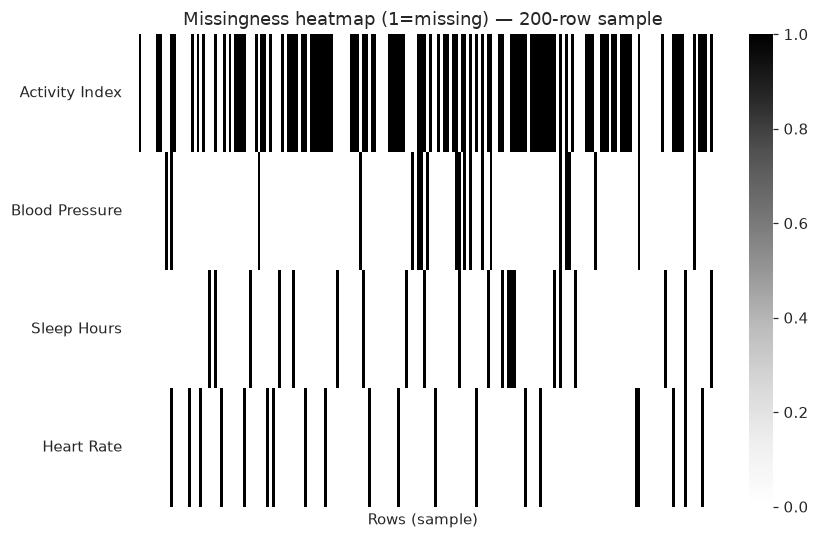

Dark = missing. Activity Index missingness is widespread; BP gaps are sparser (including former zeros).


In [7]:
# Simple missingness heatmap (sample of rows × high-missing columns)
miss_cols = ['Activity Index', 'Blood Pressure', 'Sleep Hours', 'Heart Rate']
sample = df_clean[miss_cols].isna().astype(int)
# sample up to 200 rows for readability
rng = np.random.default_rng(42)
idx = rng.choice(sample.index, size=min(200, len(sample)), replace=False)
heat = sample.loc[sorted(idx)]

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heat.T, cbar=True, cmap='Greys', ax=ax,
            yticklabels=miss_cols, xticklabels=False)
ax.set_title('Missingness heatmap (1=missing) — 200-row sample')
ax.set_xlabel('Rows (sample)')
plt.tight_layout()
plt.show()
print('Dark = missing. Activity Index missingness is widespread; BP gaps are sparser (including former zeros).')


### Imputation note (for modelling)

Gaps look like recording issues, not a clear High/Low pattern from the missingness heatmap.  
**Plan for ML:** median-impute numerics on the **training set only** (robust on skewed health data; one consistent rule).


---
## Section 2 — Univariate look

Quick shape check per column, then class balance.


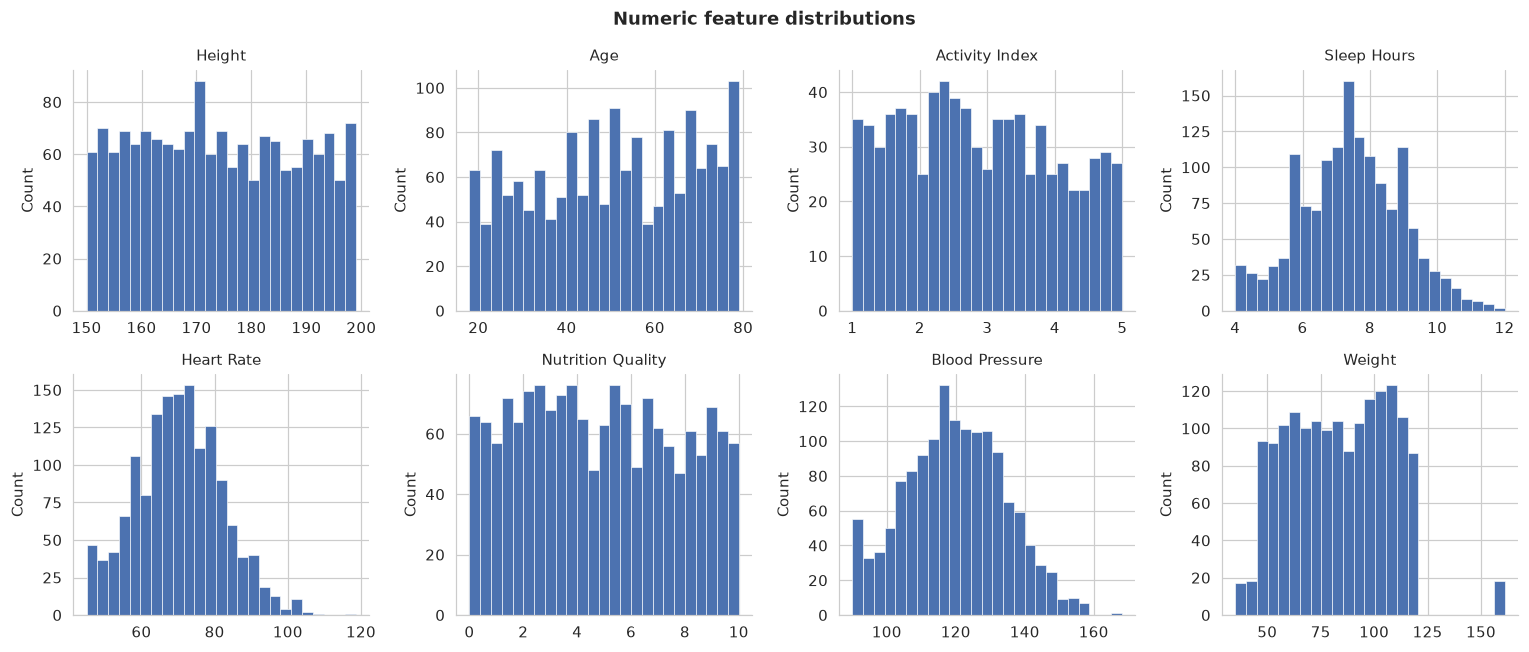

Weight and Blood Pressure look most skewed / spiked — matches the anomalies we already clipped or set to NaN.


In [8]:
numeric_cols = ['Height', 'Age', 'Activity Index', 'Sleep Hours',
                'Heart Rate', 'Nutrition Quality', 'Blood Pressure', 'Weight']

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    axes[i].hist(df_clean[col].dropna(), bins=25,
                 color='#4C72B0', edgecolor='white', linewidth=0.4)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel('Count')
    for sp in ['top', 'right']:
        axes[i].spines[sp].set_visible(False)
plt.suptitle('Numeric feature distributions', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('Weight and Blood Pressure look most skewed / spiked — matches the anomalies we already clipped or set to NaN.')


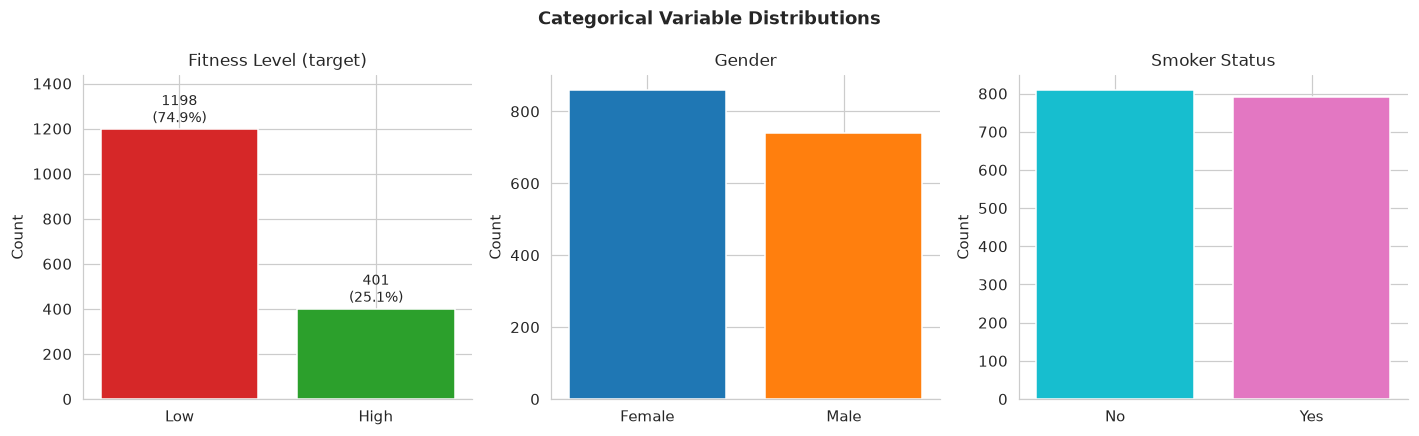

In [9]:
# categorical variable counts — class balance matters a lot for modelling
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Fitness Level
fl = df_clean['Fitness Level'].value_counts()
axes[0].bar(fl.index, fl.values, color=['#d62728', '#2ca02c'])
for rect, v in zip(axes[0].patches, fl.values):
    pct = v / fl.sum() * 100
    axes[0].text(
        rect.get_x() + rect.get_width()/2,
        rect.get_height() + 10,
        f'{v}\n({pct:.1f}%)',
        ha='center', va='bottom', fontsize=9
    )
axes[0].set_title('Fitness Level (target)', fontsize=11)
axes[0].set_ylim(0, fl.max() * 1.2)

# Gender
g = df_clean['Gender'].value_counts()
axes[1].bar(g.index, g.values, color=['#1f77b4', '#ff7f0e'])
axes[1].set_title('Gender', fontsize=11)

# Smoker
s = df_clean['Smoker'].value_counts()
axes[2].bar(s.index, s.values, color=['#17becf', '#e377c2'])
axes[2].set_title('Smoker Status', fontsize=11)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylabel('Count')

plt.suptitle('Categorical Variable Distributions', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

> **Class imbalance:** roughly **3:1 Low:High**. A model that always predicts Low looks accurate (~75%) but learns nothing. Stratified splits + an imbalance method (SMOTE in ML) matter.


---
## Section 3 — Exploring patterns

Three layers: **feature → target**, **feature → feature**, then a light **K-Means** look at natural groups.


### 3.1 Feature → target (one feature at a time)

Does Activity Index or smoking line up with High vs Low fitness?


               count   mean  median
Fitness Level                      
High             190  3.533   3.520
Low              602  2.668   2.515



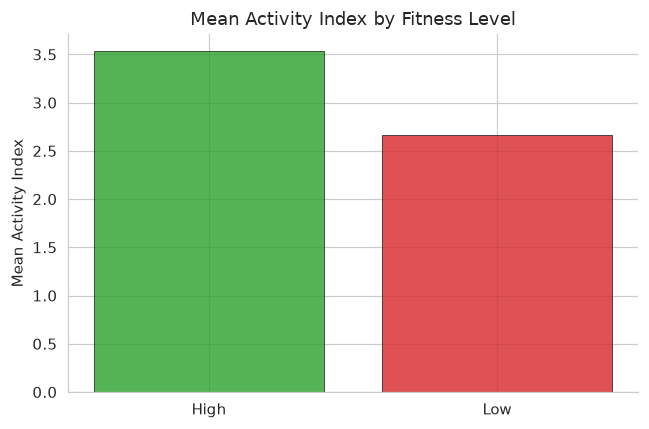

High group averages ~3.5 vs Low ~2.7 — activity clearly separates the classes on average.


In [10]:
# Mean Activity Index by Fitness Level — simple table + bar
ai_summary = df_clean.groupby("Fitness Level")["Activity Index"].agg(["count", "mean", "median"])
print(ai_summary.round(3))
print()

order = ["High", "Low"]
means = df_clean.groupby("Fitness Level")["Activity Index"].mean().reindex(order)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(order, means.values, color=["#2ca02c", "#d62728"], alpha=0.8, edgecolor="black", linewidth=0.5)
ax.set_ylabel("Mean Activity Index")
ax.set_title("Mean Activity Index by Fitness Level")
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.show()
print("High group averages ~3.5 vs Low ~2.7 — activity clearly separates the classes on average.")


Counts:
Fitness Level  High  Low
Smoker                  
No              295  513
Yes             106  685

% High fitness within smoker group:
Smoker
No     36.5
Yes    13.4
dtype: float64


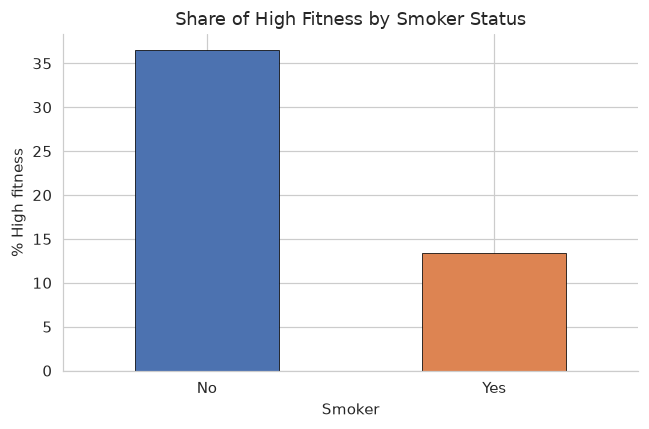

Non-smokers ~36% High vs smokers ~13% High — smoking is a strong, easy-to-see signal.


In [11]:
# Smoker crosstab — what % of each smoker group is High fitness?
ct = pd.crosstab(df_clean["Smoker"], df_clean["Fitness Level"])
print("Counts:")
print(ct)
print()
pct_high = (ct["High"] / ct.sum(axis=1) * 100).round(1)
print("% High fitness within smoker group:")
print(pct_high)

fig, ax = plt.subplots(figsize=(6, 4))
pct_high.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"], edgecolor="black", linewidth=0.5)
ax.set_ylabel("% High fitness")
ax.set_title("Share of High Fitness by Smoker Status")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.show()
print("Non-smokers ~36% High vs smokers ~13% High — smoking is a strong, easy-to-see signal.")


### 3.2 Feature → feature (two features together)

Do lifestyle signals travel together? Do age and body size form a visible pattern when coloured by fitness?


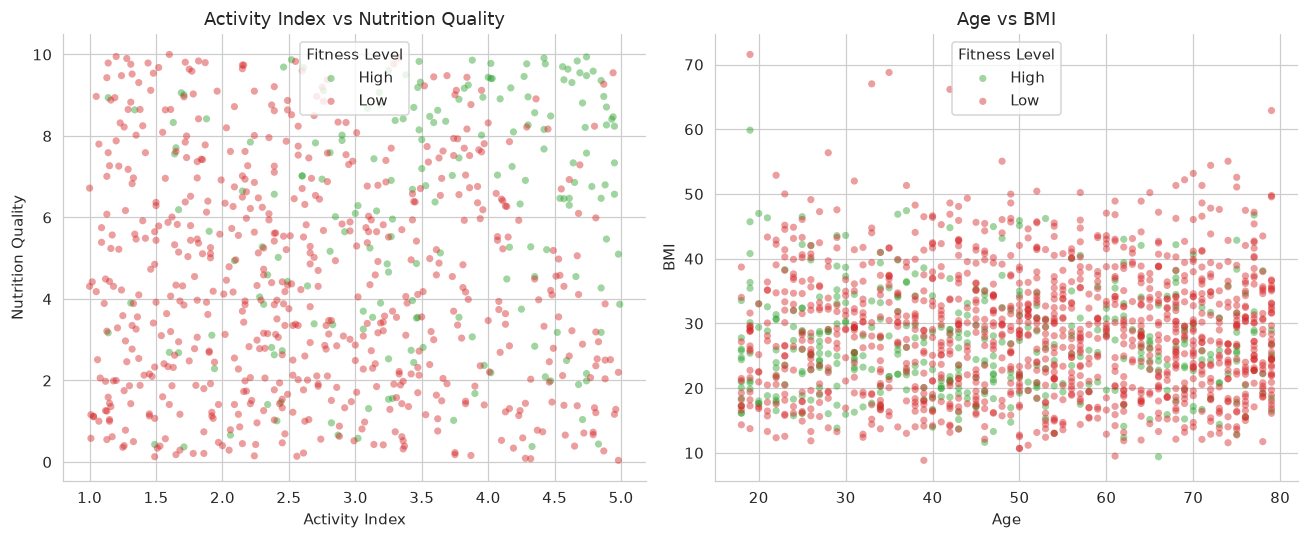

Activity + nutrition: High points lean higher, but lots of overlap — the signal is real but noisy.
Age + BMI: High group looks a bit younger/lighter on average; again, plenty of mix.


In [12]:
# Need BMI for the age–BMI scatter
df_clean["BMI"] = df_clean["Weight"] / ((df_clean["Height"] / 100) ** 2)

color_map = {"High": "#2ca02c", "Low": "#d62728"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for level, grp in df_clean.groupby("Fitness Level"):
    axes[0].scatter(grp["Activity Index"], grp["Nutrition Quality"],
                    c=color_map[level], alpha=0.45, s=22, label=level, edgecolors="none")
axes[0].set_xlabel("Activity Index")
axes[0].set_ylabel("Nutrition Quality")
axes[0].set_title("Activity Index vs Nutrition Quality")
axes[0].legend(title="Fitness Level")

for level, grp in df_clean.groupby("Fitness Level"):
    axes[1].scatter(grp["Age"], grp["BMI"],
                    c=color_map[level], alpha=0.45, s=22, label=level, edgecolors="none")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("BMI")
axes[1].set_title("Age vs BMI")
axes[1].legend(title="Fitness Level")

for ax in axes:
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

plt.tight_layout()
plt.show()
print("Activity + nutrition: High points lean higher, but lots of overlap — the signal is real but noisy.")
print("Age + BMI: High group looks a bit younger/lighter on average; again, plenty of mix.")


### 3.3 More feature → feature checks

Even if a pair is weak for prediction, it still shows how the dataset is structured.


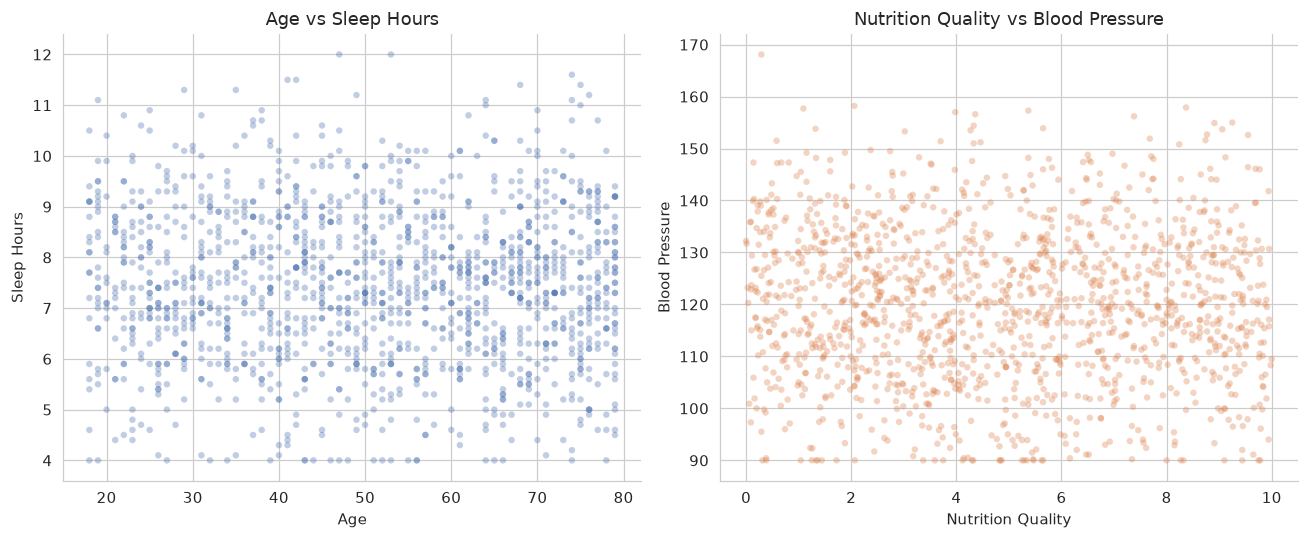

Age–Sleep: no sharp trend — sleep is fairly flat across ages in this sample.
Nutrition–BP: cloud with little clear slope — nutrition and BP are mostly independent here.


In [13]:
# BMI already created above
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Sleep vs Age — lifestyle / life-stage structure
axes[0].scatter(df_clean['Age'], df_clean['Sleep Hours'],
                c='#4C72B0', alpha=0.35, s=18, edgecolors='none')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Sleep Hours')
axes[0].set_title('Age vs Sleep Hours')

# Nutrition vs Blood Pressure — health behaviours vs reading
axes[1].scatter(df_clean['Nutrition Quality'], df_clean['Blood Pressure'],
                c='#DD8452', alpha=0.35, s=18, edgecolors='none')
axes[1].set_xlabel('Nutrition Quality')
axes[1].set_ylabel('Blood Pressure')
axes[1].set_title('Nutrition Quality vs Blood Pressure')

for ax in axes:
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.show()
print('Age–Sleep: no sharp trend — sleep is fairly flat across ages in this sample.')
print('Nutrition–BP: cloud with little clear slope — nutrition and BP are mostly independent here.')


### 3.4 Group profile (feature → target summary)

Mean profile of High vs Low — the cheat sheet for what differs.


In [14]:
profile_cols = ["Activity Index", "Nutrition Quality", "Age", "Sleep Hours", "BMI"]
profile = df_clean.groupby("Fitness Level")[profile_cols].mean().round(2)
print(profile)
print()
print("Biggest jumps High vs Low: Activity Index and Nutrition Quality. Age is next. Sleep barely moves.")


               Activity Index  Nutrition Quality    Age  Sleep Hours    BMI
Fitness Level                                                              
High                     3.53               6.05  45.30         7.60  26.65
Low                      2.67               4.45  52.29         7.38  28.65

Biggest jumps High vs Low: Activity Index and Nutrition Quality. Age is next. Sleep barely moves.


### 3.5 Feature → target visuals (boxplots)

Same idea as the profile table, but showing spread as well as the centre.


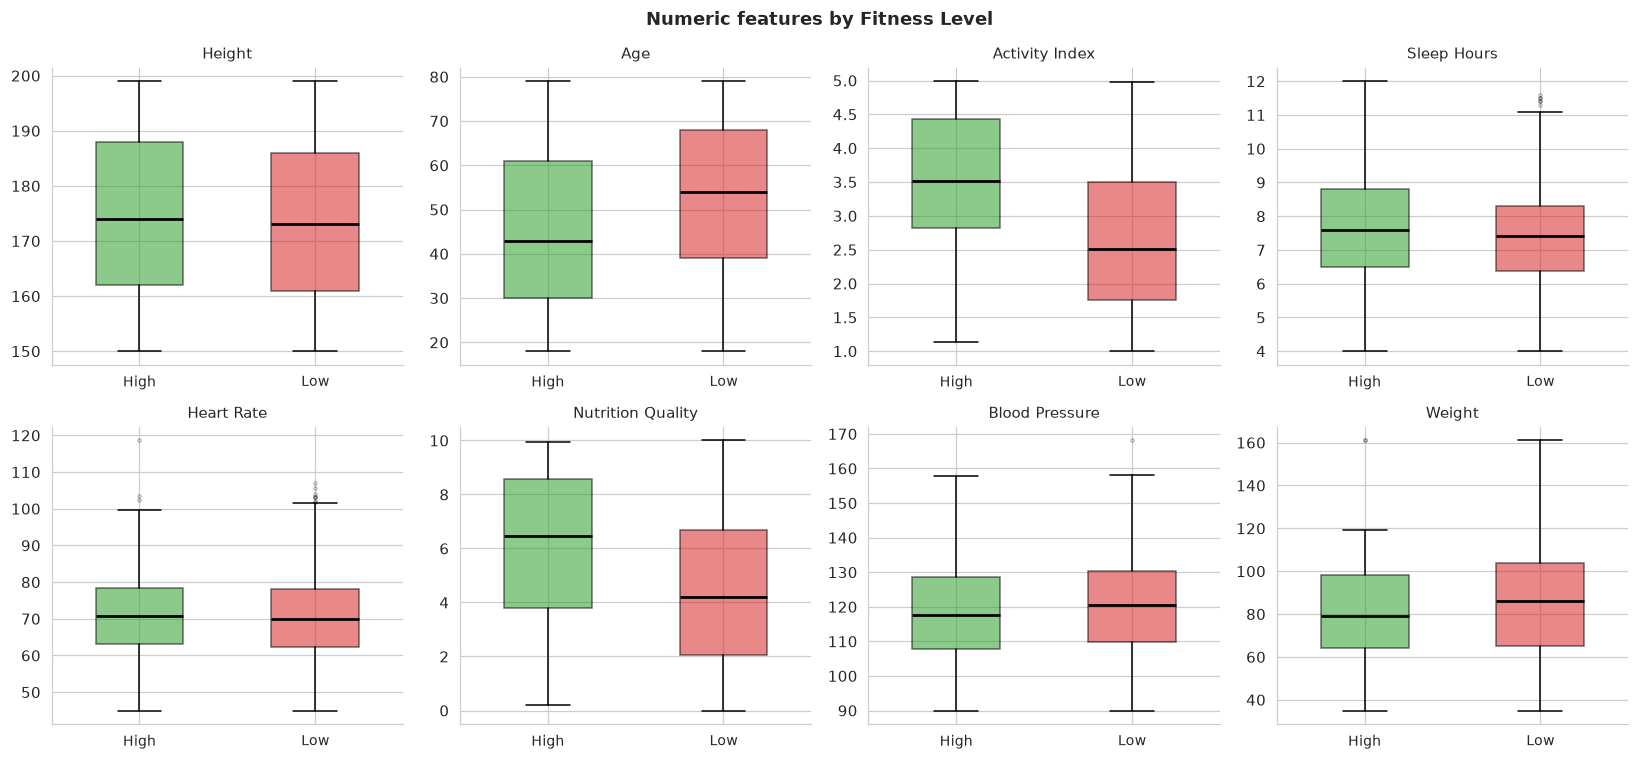

Clearest separation: Activity Index and Nutrition Quality. Age shifts a bit. Height / Heart Rate barely move.


In [15]:
group_colors = {'High': '#2ca02c', 'Low': '#d62728'}
pos_map = {'High': 0, 'Low': 1}

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    ax = axes[i]
    for level, grp in df_clean.groupby('Fitness Level'):
        vals = grp[col].dropna().values
        ax.boxplot(
            vals, positions=[pos_map[level]], widths=0.5, patch_artist=True,
            boxprops=dict(facecolor=group_colors[level], alpha=0.55),
            medianprops=dict(color='black', linewidth=1.8),
            flierprops=dict(marker='o', markersize=2, alpha=0.25),
        )
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['High', 'Low'], fontsize=9)
    ax.set_title(col, fontsize=10)
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)
plt.suptitle('Numeric features by Fitness Level', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('Clearest separation: Activity Index and Nutrition Quality. Age shifts a bit. Height / Heart Rate barely move.')


### 3.6 Gender → target (simple rate)

Same style as smoker: what share of each gender is High fitness?


Fitness Level  High  Low
Gender                  
Female          169  689
Male            232  508

% High within gender:
Gender
Female    19.7
Male      31.4
dtype: float64


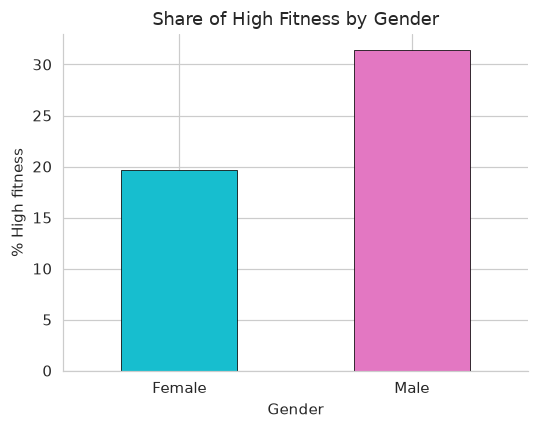

Males show a higher High-fitness share than females in this sample — smaller gap than smoking, but visible.


In [16]:
ct_g = pd.crosstab(df_clean['Gender'], df_clean['Fitness Level'])
print(ct_g)
pct_g = (ct_g['High'] / ct_g.sum(axis=1) * 100).round(1)
print('\n% High within gender:')
print(pct_g)

fig, ax = plt.subplots(figsize=(5, 4))
pct_g.plot(kind='bar', ax=ax, color=['#17becf', '#e377c2'], edgecolor='black', linewidth=0.5)
ax.set_ylabel('% High fitness')
ax.set_title('Share of High Fitness by Gender')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.show()
print('Males show a higher High-fitness share than females in this sample — smaller gap than smoking, but visible.')


### 3.7 Feature ↔ feature correlation

Are any numeric columns basically copies of each other?


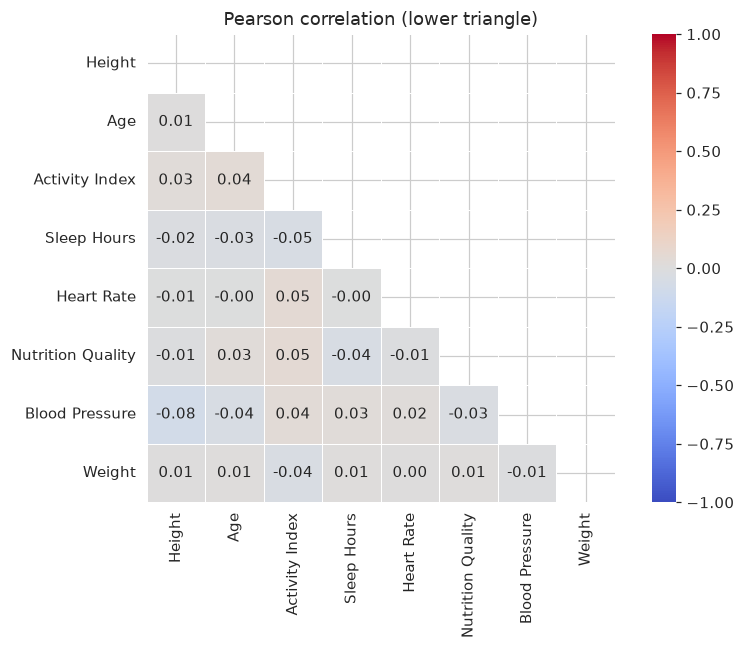

No pair is extremely correlated (|r| stays modest). Height and Weight relate a bit — that is why BMI is a cleaner single feature later.


In [17]:
corr = df_clean[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, ax=ax, square=True, linewidths=0.5)
ax.set_title('Pearson correlation (lower triangle)')
plt.tight_layout()
plt.show()
print('No pair is extremely correlated (|r| stays modest). Height and Weight relate a bit — that is why BMI is a cleaner single feature later.')


### 3.8 Simple clustering (k=3)

Do natural groups appear that match High/Low? Light K-Means — exploration only, not used as an ML feature.


Complete cases used: 792

Cluster means:
           Age  Activity Index  Nutrition Quality    BMI
Cluster                                                 
0        52.71            3.04               8.03  29.20
1        64.87            3.12               2.99  27.95
2        32.45            2.40               3.33  27.91

% High / Low inside each cluster:
Fitness Level  High   Low
Cluster                  
0              38.1  61.9
1              14.8  85.2
2              18.9  81.1


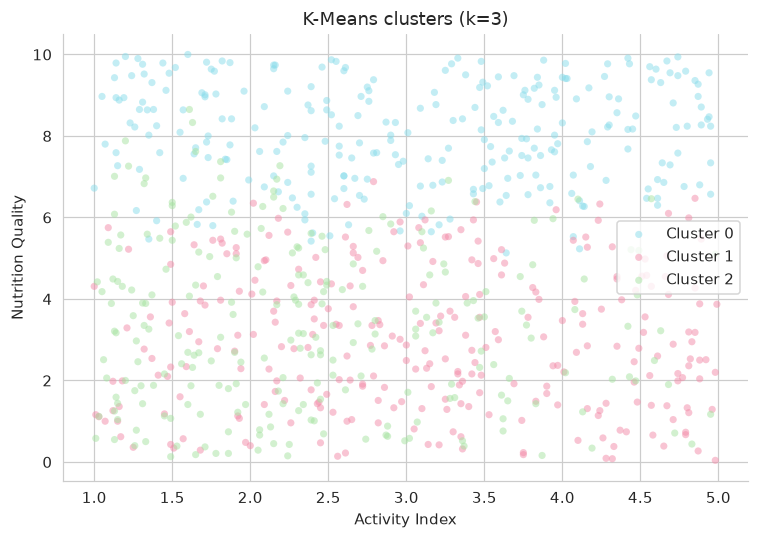

Clusters do not map cleanly onto High/Low — fitness labels overlap in feature space. Useful context before modelling.


In [18]:
cluster_feats = ["Age", "Activity Index", "Nutrition Quality", "BMI"]
sub = df_clean[cluster_feats + ["Fitness Level"]].dropna().copy()
print(f"Complete cases used: {len(sub)}")

X_c = StandardScaler().fit_transform(sub[cluster_feats])
km = KMeans(n_clusters=3, random_state=42, n_init=10)
sub["Cluster"] = km.fit_predict(X_c)

print("\nCluster means:")
print(sub.groupby("Cluster")[cluster_feats].mean().round(2))

print("\n% High / Low inside each cluster:")
comp = (sub.groupby("Cluster")["Fitness Level"].value_counts(normalize=True)
          .unstack(fill_value=0) * 100).round(1)
print(comp)

cluster_colors = ["#89dceb", "#f38ba8", "#a6e3a1"]
fig, ax = plt.subplots(figsize=(7, 5))
for k in range(3):
    m = sub["Cluster"] == k
    ax.scatter(sub.loc[m, "Activity Index"], sub.loc[m, "Nutrition Quality"],
               c=cluster_colors[k], alpha=0.5, s=22, label=f"Cluster {k}", edgecolors="none")
ax.set_xlabel("Activity Index")
ax.set_ylabel("Nutrition Quality")
ax.set_title("K-Means clusters (k=3)")
ax.legend()
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.show()
print("Clusters do not map cleanly onto High/Low — fitness labels overlap in feature space. Useful context before modelling.")


---
## Section 4 — Synthesis

What matters before modelling?


In [19]:
print('=== What jumped out ===')
print()
findings = [
    ('Activity Index',  'Strongest lifestyle signal — High group averages clearly higher.'),
    ('Nutrition Quality','Second clear separator on plots and means.'),
    ('Smoker',          'Non-smokers much more often High (~36% vs ~13%).'),
    ('Age',             'High group a bit younger on average.'),
    ('Gender',          'Visible but smaller High-rate gap than smoking.'),
    ('Height / HR',     'Little separation — weak for predicting Fitness Level.'),
    ('Sleep',           'Means barely differ; Age–Sleep scatter is flat.'),
    ('Corr structure',  'No scary multicollinearity; BMI replaces Height+Weight cleanly.'),
    ('Clusters',        'K-Means groups do not map cleanly onto High/Low — labels overlap.'),
]
print(f'{"Topic":<20}  Insight')
print('-' * 88)
for topic, note in findings:
    print(f'{topic:<20}  {note}')

print()
print('=== Pre-Modelling Checklist (handoff to Resub 2) ===')
print()
checklist = [
    'DROP: ghost rows (>=80% NaN) + exact duplicates  [done in Section 1]',
    'BP==0 → NaN then median-impute in ML  [done in Section 1]',
    'CLIP: Weight to [35, 161]  [done in Section 1]',
    'KEEP: HR>100 and Sleep>9.5 (plausible)  [documented]',
    'IMPUTE: median on training set only',
    'ENGINEER: BMI; drop raw Height/Weight (and weak Heart Rate) in the model',
    'STRATIFY + SMOTE in ML for ~3:1 imbalance',
]
for item in checklist:
    print(f'  - {item}')


=== What jumped out ===

Topic                 Insight
----------------------------------------------------------------------------------------
Activity Index        Strongest lifestyle signal — High group averages clearly higher.
Nutrition Quality     Second clear separator on plots and means.
Smoker                Non-smokers much more often High (~36% vs ~13%).
Age                   High group a bit younger on average.
Gender                Visible but smaller High-rate gap than smoking.
Height / HR           Little separation — weak for predicting Fitness Level.
Sleep                 Means barely differ; Age–Sleep scatter is flat.
Corr structure        No scary multicollinearity; BMI replaces Height+Weight cleanly.
Clusters              K-Means groups do not map cleanly onto High/Low — labels overlap.

=== Pre-Modelling Checklist (handoff to Resub 2) ===

  - DROP: ghost rows (>=80% NaN) + exact duplicates  [done in Section 1]
  - BP==0 → NaN then median-impute in ML  [done in Sect

### Bottom Line

**Activity Index**, **Nutrition Quality**, and **Smoker** are the clearest patterns versus Fitness Level. Age helps a little; Height and resting Heart Rate barely do.

Feature–feature plots show a fairly loose structure (sleep does not track age strongly; nutrition and BP are mostly independent). Correlation is mild, so combining a few lifestyle features is reasonable. K-Means finds groups, but they do **not** line up neatly with High/Low — the classes overlap in feature space.

Biggest modelling risk remains **~50% missing Activity Index**, plus the **3:1 class imbalance**. Quality fixes (ghost/dups, BP 0→NaN, Weight clip) are already decided above for the ML notebook.
